<center><h1>1-cde: Convolutional Neural Networks & an introduction to Vision Transformers</h1></center>

<center><h2><a href="https://rdfia.github.io/">Course link</a></h2></center>

# Warning :
# Do "File -> Save a copy in Drive" before you start modifying the notebook, otherwise your modifications will not be saved.

**Runtime → Change runtime type → GPU** before starting.

## Goals

The objective of this lab is to become familiar with **convolutional neural networks** (CNNs), the reference
architecture for images, and to get a **first contact with Vision Transformers** (ViT).

1. **Part 0 – Warm-up** : convolution and pooling arithmetic.
2. **Part 1 – Training a CNN from scratch** on CIFAR-10.
3. **Part 2 – Improving the CNN**: normalization, data augmentation, batch normalization, dropout, and
   black-box testing of layers.
4. **Part 3 – Introduction to Vision Transformers**: patch embedding, self-attention, black-box testing,
   ViT on the same data.

The same data pipeline and the same training loop are used for every model, so that the final comparison is fair.

Questions marked ★ must be answered in your report and will be graded.


## Setup

In [1]:
import time
import math

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.backends.cudnn as cudnn
import torch.utils.data
import torchvision.transforms as transforms
import torchvision.datasets as datasets

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using", device)

PRINT_INTERVAL = 100
PATH = "datasets"

Using cuda


A few utilities to compute and plot metrics (you do not need to modify them).

In [2]:
def accuracy(output, target, topk=(1,)):
    # Computes the precision@k (in %) for the specified values of k.
    # precision@k (or top-k accuracy) is the percentage of examples whose true class is among
    # the k classes with the highest scores; precision@1 is the usual accuracy.
    maxk = max(topk)
    batch_size = target.size(0)
    _, pred = output.topk(maxk, 1, True, True)
    pred = pred.t()
    correct = pred.eq(target.view(1, -1).expand_as(pred))
    return [correct[:k].reshape(-1).float().sum() * 100.0 / batch_size for k in topk]


class AverageMeter(object):
    # Computes and stores the average and current value
    def __init__(self):
        self.val, self.avg, self.sum, self.count = 0, 0, 0, 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count


class AccLossPlot(object):
    # Train/test accuracy and loss curves, redrawn at the end of each epoch
    def __init__(self, title=""):
        self.title = title
        self.loss_train, self.loss_test, self.acc_train, self.acc_test = [], [], [], []

    def update(self, loss_train, loss_test, acc_train, acc_test):
        self.loss_train.append(loss_train)
        self.loss_test.append(loss_test)
        self.acc_train.append(acc_train)
        self.acc_test.append(acc_test)
        clear_output(wait=True)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
        ax1.plot(self.acc_train, label="acc. train")
        ax1.plot(self.acc_test, label="acc. test")
        ax1.set_title(f"{self.title} Accuracy / epoch"); ax1.set_xlabel("Epoch"); ax1.legend()
        ax2.plot(self.loss_train, label="loss train")
        ax2.plot(self.loss_test, label="loss test")
        ax2.set_title(f"{self.title} Loss / epoch"); ax2.set_xlabel("Epoch"); ax2.legend()
        plt.show()
        plt.close(fig)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Sections 2.3 and 3.3 use **black-box layers**: compiled code that you can use but not read. The cell below downloads
the version matching your Python.

In [3]:
import sys
import sysconfig
import urllib.request

# One compiled file per Python version (3.10 to 3.13, Linux x86-64): we download the one matching this runtime
MYSTERY_URL = "https://github.com/rdfia/rdfia.github.io/raw/master/code/1-cde/"
filename = "mystery_layers" + sysconfig.get_config_var("EXT_SUFFIX")
try:
    urllib.request.urlretrieve(MYSTERY_URL + filename, filename)
except urllib.error.HTTPError as e:
    raise RuntimeError(f"Could not download {filename} ({e}). Python {sys.version.split()[0]} on {sys.platform} "
                       "may not be supported: use Colab, or ask your teacher.") from e
import mystery_layers
print("mystery_layers loaded")

mystery_layers loaded


# Part 0 – Warm-up: convolution and pooling

**Convolutional layers.** A convolution layer takes as input $D$ feature maps of size $n_x \times n_y$ (a tensor
$n_x \times n_y \times D$) and applies $C$ filters of size $k \times k \times D$, producing $C$ output feature maps.
Besides $C$ and the kernel size $k$, its hyper-parameters are the **padding** $p$ (number of rows/columns of zeros
added around the input) and the **stride** $s$ (step between two positions of the filter).

**Pooling layers.** Pooling spatially downsamples each feature map independently, with a sliding window
(kernel size, stride, padding) and an operation such as *max* or *average*. It has no learnable parameter.
The most common one is a max-pooling with kernel 2, stride 2 and no padding.

**Classical architectures** (e.g. VGG16) stack convolutions + ReLU with more and more filters, while max-poolings
progressively reduce the spatial size; one or a few fully-connected (FC) layers end the network.

See the [convolution arithmetic guide](https://arxiv.org/abs/1603.07285) (Dumoulin & Visin, 2016) for illustrations.

### Questions
1. ★ For a single convolution filter with padding $p$, stride $s$ and kernel size $k$, and an input of size
   $x \times y \times z$: what is the output size? How many weights are there to learn? How many weights would a
   fully-connected layer producing an output of the same size need?
2. ★ What are the advantages of convolution over fully-connected layers? What is its main limit?
3. ★ Why do we use spatial pooling?
4. ★ The *receptive field* of a neuron is the set of input pixels its output depends on. For the CIFAR-10 network
   of Part 1, what is the receptive field of a neuron of `conv1`? of `conv2`? What happens for deeper layers, and
   how can it be interpreted?
5. We feed a classical CNN (e.g. VGG16, designed for 224×224 inputs) with a larger image. Can we (without
   modifying the image) use all or part of the network's layers on it? *(Keep your answer in mind for Part 4.)*

# Part 1 – Training a CNN from scratch

## 1.1 Starting point: LeNet-5 on MNIST

The code below trains a small historical CNN, LeNet-5, on MNIST. Read it carefully: the training loop
(`epoch` and `main`) will be reused **unchanged** for every model of this lab, including the transformer.

In [4]:
class LeNet5(nn.Module):
    # This class defines the structure of the neural network

    def __init__(self):
        super().__init__()
        # We first define the convolution and pooling layers as a features extractor
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, (5, 5), stride=1, padding=2),
            nn.Tanh(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),
            nn.Conv2d(6, 16, (5, 5), stride=1, padding=0),
            nn.Tanh(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),
        )
        # We then define fully connected layers as a classifier
        self.classifier = nn.Sequential(
            nn.Linear(400, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
            # Reminder: The softmax is included in the loss, do not put it here
        )

    # Method called when we apply the network to an input batch
    def forward(self, input):
        bsize = input.size(0)  # batch size
        output = self.features(input)  # output of the conv layers
        output = output.view(bsize, -1)  # we flatten the 2D feature maps into one 1D vector for each input
        output = self.classifier(output)  # we compute the output of the fc layers
        return output

`get_dataset` loads the data and applies the transformations listed in `transform`. You will complete it
in 1.2 (CIFAR-10) and in Part 2 (normalization, data augmentation).

In [5]:
def get_dataset(name, batch_size, normalize=False, augment=False):
    # Loads the dataset `name` ("mnist" or "cifar10") and performs transformations on each image.
    if name == "mnist":
        train_transform = test_transform = transforms.ToTensor()
        train_dataset = datasets.MNIST(PATH, train=True, download=True, transform=train_transform)
        test_dataset = datasets.MNIST(PATH, train=False, download=True, transform=test_transform)

    elif name == "cifar10":
        train_transform = [transforms.ToTensor()]
        test_transform = [transforms.ToTensor()]

        # TODO (Part 2.1): if normalize, add a per-channel normalization to both train and test
        if normalize:
            norm = transforms.Normalize(mean=[0.491, 0.482, 0.447], std=[0.202, 0.199, 0.201])
            train_transform.append(norm)
            test_transform.append(norm)

        # TODO (Part 2.2): if augment, add a random 28x28 crop and a random horizontal flip in train,
        #                  and a centered 28x28 crop in test (careful with the order w.r.t. ToTensor)
        if augment:
            train_transform = [transforms.RandomCrop(28), transforms.RandomHorizontalFlip()] + train_transform
            test_transform = [transforms.CenterCrop(28)] + test_transform

        train_transform = transforms.Compose(train_transform)
        test_transform = transforms.Compose(test_transform)

        # TODO (Part 1.2): create the CIFAR-10 train and test datasets (class datasets.CIFAR10)
        train_dataset = datasets.CIFAR10(PATH, train=True, download=True, transform=train_transform)
        test_dataset = datasets.CIFAR10(PATH, train=False, download=True, transform=test_transform)

    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                                               pin_memory=(device == "cuda"), num_workers=2)
    test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                                              pin_memory=(device == "cuda"), num_workers=2)
    return train_loader, test_loader

In [6]:
def epoch(data, model, criterion, optimizer=None):
    # Make a pass (called epoch in English) on the data `data` with the model `model`.
    # Evaluates `criterion` as loss. If `optimizer` is given, perform a training epoch using
    # the given optimizer, otherwise, perform an evaluation epoch (no backward) of the model.

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_batch_time = AverageMeter()

    # we iterate on the batches
    tic = time.time()
    with torch.set_grad_enabled(optimizer is not None):
        for i, (input, target) in enumerate(data):
            input, target = input.to(device), target.to(device)

            # forward
            output = model(input)
            loss = criterion(output, target)

            # backward if we are training
            if optimizer:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            # compute metrics
            prec1, = accuracy(output, target)
            batch_time = time.time() - tic
            tic = time.time()

            # update
            avg_loss.update(loss.item())
            avg_top1_acc.update(prec1.item())
            avg_batch_time.update(batch_time)

            if optimizer and i % PRINT_INTERVAL == 0:
                print('[TRAIN Batch {0:03d}/{1:03d}]\t'
                      'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                      'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})'.format(
                       i, len(data), loss=avg_loss, top1=avg_top1_acc))

    return avg_top1_acc.avg, avg_loss.avg, avg_batch_time.sum


def main(model, train_loader, test_loader, optimizer, epochs=10, lr_sched=None, title=""):
    # Trains `model` with `optimizer` and evaluates it on the test set after each epoch.
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    if device == "cuda":
        cudnn.benchmark = True

    print(f"{count_parameters(model):,} trainable parameters")
    plot = AccLossPlot(title)

    # We iterate on the epochs
    for i in range(epochs):
        # Train phase
        acc_train, loss_train, t = epoch(train_loader, model, criterion, optimizer)
        # Test phase
        acc_test, loss_test, _ = epoch(test_loader, model, criterion)
        if lr_sched:
            lr_sched.step()
        # plot
        plot.update(loss_train, loss_test, acc_train, acc_test)
        print(f"Epoch {i + 1}/{epochs} ({int(t)}s)\t"
              f"train: loss {loss_train:.4f}, acc {acc_train:5.2f}%\t"
              f"test: loss {loss_test:.4f}, acc {acc_test:5.2f}%")
    return acc_test

### Questions
6. Read and run the code below (2 epochs are enough).
7. ★ In the provided code, what is the major difference between the way loss and accuracy are computed in train
   and in test (other than the difference in data)?

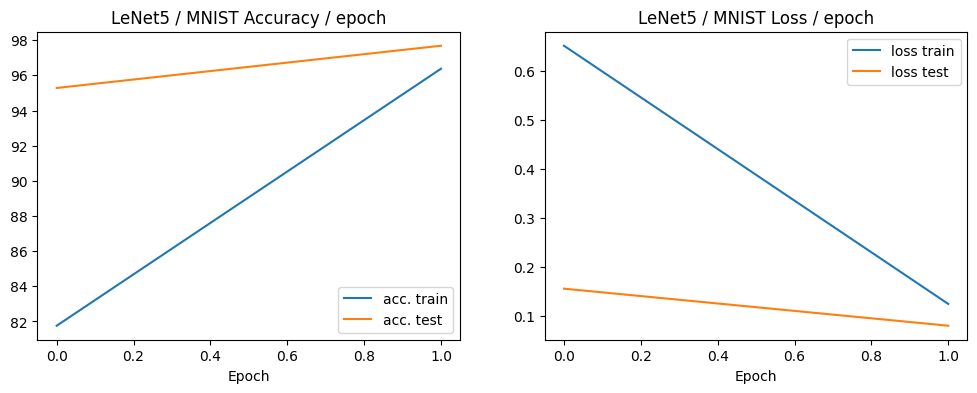

Epoch 2/2 (7s)	train: loss 0.1244, acc 96.38%	test: loss 0.0800, acc 97.69%


97.68591772151899

In [7]:
train_loader, test_loader = get_dataset("mnist", batch_size=128)
model = LeNet5()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
main(model, train_loader, test_loader, optimizer, epochs=2, title="LeNet5 / MNIST")

## 1.2 A CNN for CIFAR-10

We now train our own network on [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html): 32×32 RGB images,
10 classes, 50k training and 10k test images. Its style is close to AlexNet, adapted to the small images:

| layer | description |
|---|---|
| `conv1` | 32 convolutions 5×5, followed by ReLU |
| `pool1` | max-pooling 2×2 |
| `conv2` | 64 convolutions 5×5, followed by ReLU |
| `pool2` | max-pooling 2×2 |
| `conv3` | 64 convolutions 5×5, followed by ReLU |
| `pool3` | max-pooling 2×2 (use `ceil_mode=True`: no effect on 32×32 inputs, needed in Part 2) |
| `fc4` | fully-connected, 1000 outputs, followed by ReLU |
| `fc5` | fully-connected, 10 outputs, followed by softmax (included in the loss) |

### Questions
8. ★ For the convolutions, we want the output to have the same spatial size as the input. Using your formula of
   question 1, derive the padding and stride needed for a 5×5 kernel, then for any odd kernel size $k$.
   Why is it harder with an even kernel size? For the max-poolings, we want to divide the spatial size by 2:
   what padding and stride are needed?
9. ★ For each layer, give the output size and the number of weights to learn. Comment on this distribution.
   What is the total number of weights? Compare it to the number of training examples.
10. Complete `get_dataset` for CIFAR-10 and implement the network below. Check your answer to question 9 with
    `count_parameters`.

In [8]:
class ConvNetCIFAR(nn.Module):

    def __init__(self, batchnorm=False, dropout=0.0):
        # batchnorm and dropout are only used in Part 2: ignore them for now
        super().__init__()
        # TODO: convolution and pooling layers
        layers = []
        for c_in, c_out, ceil in [(3, 32, False), (32, 64, False), (64, 64, True)]:
            layers.append(nn.Conv2d(c_in, c_out, (5, 5), stride=1, padding=2))
            if batchnorm:
                layers.append(nn.BatchNorm2d(c_out))
            layers.append(nn.ReLU())
            layers.append(nn.MaxPool2d((2, 2), stride=2, padding=0, ceil_mode=ceil))
        self.features = nn.Sequential(
            *layers
        )
        # TODO: fully connected layers
        fc_layers = [nn.Linear(64 * 4 * 4, 1000), nn.ReLU()]
        if dropout > 0.0:
            fc_layers.append(nn.Dropout(dropout))
        fc_layers.append(nn.Linear(1000, 10))
        self.classifier = nn.Sequential(
            *fc_layers
        )

    def forward(self, input):
        bsize = input.size(0)
        output = self.features(input)
        output = output.view(bsize, -1)
        output = self.classifier(output)
        return output


model = ConvNetCIFAR()
print(model(torch.randn(8, 3, 32, 32)).shape)  # should be (8, 10)
print(f"{count_parameters(model):,} parameters")

torch.Size([8, 10])
1,191,170 parameters


### Questions
11. Train the network (≈20 epochs, so that it converges). What are the effects of the learning rate and of
    the batch size? *(Try one or two other values quickly if time allows.)*
12. ★ What is the error at the start of the first epoch, in train and in test? How can you interpret it?

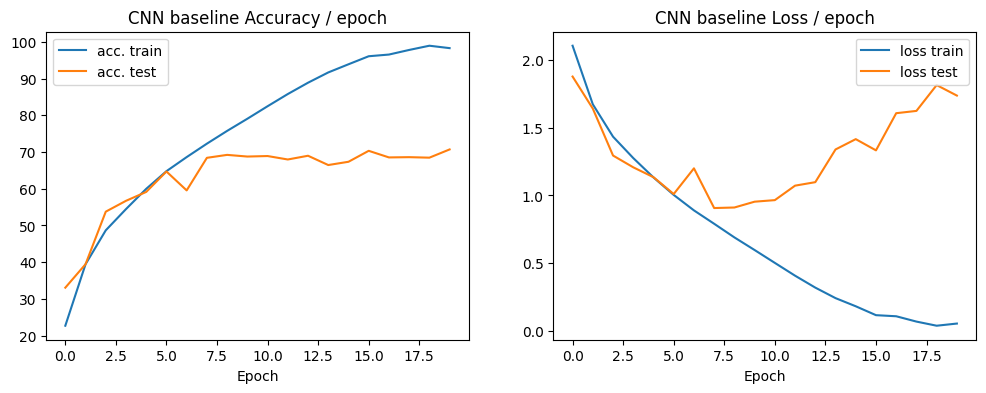

Epoch 20/20 (6s)	train: loss 0.0535, acc 98.33%	test: loss 1.7381, acc 70.72%


In [9]:
train_loader, test_loader = get_dataset("cifar10", batch_size=128)
model = ConvNetCIFAR()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
acc_baseline = main(model, train_loader, test_loader, optimizer, epochs=20, title="CNN baseline")

# Part 2 – Improving the CNN

To save time, the improvements are added **cumulatively** in two runs. ★ In your report, for each technique,
explain in one sentence its principle and why it improves learning.

## 2.1 Run A: standardization + data augmentation

**Standardization.** We standardize each RGB channel with its mean and standard deviation computed over the
training set: $\mu = [0.491, 0.482, 0.447]$, $\sigma = [0.202, 0.199, 0.201]$ (`transforms.Normalize`).

**Data augmentation.** CIFAR-10 is small compared to the number of parameters. At each epoch, we generate a
random variant of each training image: a random 28×28 crop (out of 32×32) and a random horizontal flip
(probability 1/2). Test images are center-cropped to 28×28.

**Implementation.** Complete the `normalize` and `augment` branches of `get_dataset`, then run the cell below.

### Questions
14. Why is `ceil_mode=True` needed in `pool3` once the images are cropped to 28×28?
15. Describe your results and compare them to the baseline.
16. ★ Why are the mean and standard deviation computed on the training examples only, and also used to normalize
    the test examples?
17. ★ Does the horizontal flip seem usable on all types of images? In which cases is it, or is it not?

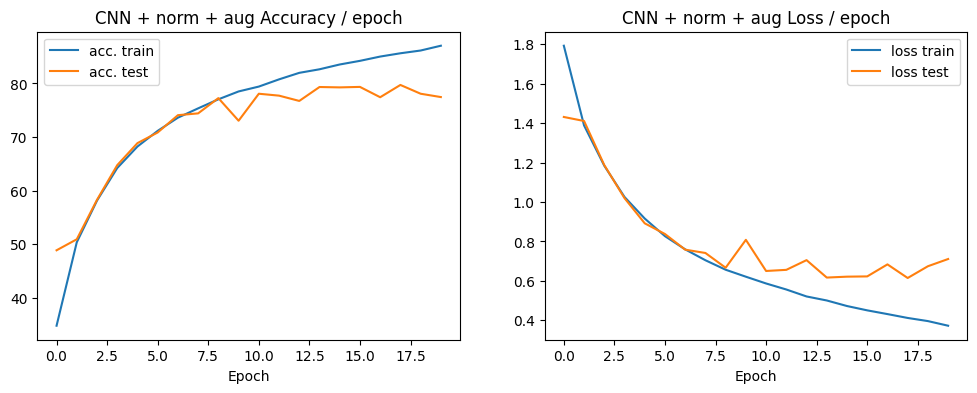

Epoch 20/20 (14s)	train: loss 0.3729, acc 87.06%	test: loss 0.7110, acc 77.46%


In [10]:
train_loader, test_loader = get_dataset("cifar10", batch_size=128, normalize=True, augment=True)
model = ConvNetCIFAR()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
acc_runA = main(model, train_loader, test_loader, optimizer, epochs=20, title="CNN + norm + aug")

## 2.2 Run B: batch normalization + dropout

**Batch normalization** (Ioffe & Szegedy, 2015) renormalizes the outputs of a layer with the statistics of the
current mini-batch, followed by a learned affine transformation; it stabilizes and speeds up training.

**Dropout** (Srivastava et al., 2014) randomly deactivates a fraction $p$ of the neurons at each forward pass in
training. Since `fc4` holds most of the weights, this is where the overfitting risk is highest.

**Implementation.** In `ConvNetCIFAR`, use the arguments `batchnorm` and `dropout`: add an `nn.BatchNorm2d`
immediately after each convolution, and an `nn.Dropout(dropout)` between `fc4` and `fc5`.

### Questions
18. Describe your results and compare them to the previous ones.
19. ★  Add a learning-rate scheduler (e.g. `torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.95)`,
    passed to `main` as `lr_sched`) or other augmentations (`ColorJitter`, `RandomErasing`…) and compare.

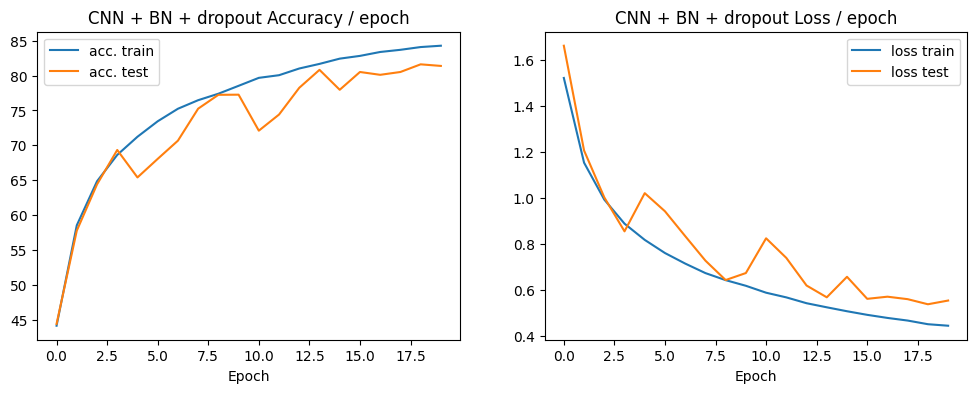

Epoch 20/20 (15s)	train: loss 0.4444, acc 84.29%	test: loss 0.5540, acc 81.39%


In [11]:
model = ConvNetCIFAR(batchnorm=True, dropout=0.5)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
acc_runB = main(model, train_loader, test_loader, optimizer, epochs=20, title="CNN + BN + dropout")

## 2.3 Black-box testing: batch normalization and dropout

`mystery_layers` contains three implementations of 2D batch normalization and three of dropout. They are compiled:
you can use them, but **not read** their code. Some are correct; others contain a *silent* bug: the shapes are
right, and a network using them would still train.

```python
bn = mystery_layers.batchnorm("A", num_features=8)  # "A", "B" or "C": same interface as nn.BatchNorm2d
do = mystery_layers.dropout("A", p=0.5)             # "A", "B" or "C": same interface as nn.Dropout
```

Your job is to design **tests**: functions that take a fresh layer and return `True` if it has a property that
*any* correct implementation must have. Start from what you know about these layers: what should they compute in
`train()` mode? in `eval()` mode? What may, and what may not, depend on the other examples of the batch?
For random layers, reason in expectation and use enough samples. Compare with tolerances (`torch.allclose`).

### Question
20. ★ Which implementations are correct? For each faulty one, give the test that exposes it, the property it
    checks, and what the bug probably is. Your tests must also pass on `nn.BatchNorm2d` and `nn.Dropout`
    (a test that rejects a correct layer is a wrong test).

In [12]:
def run_tests(make_layer, names, tests):
    # Applies each test to a fresh layer make_layer(name) and prints a table of the results
    width = max(len(t.__name__) for t in tests) + 2
    print(" " * 12 + "".join(f"{t.__name__:>{width}}" for t in tests))
    for name in names:
        row = ""
        for test in tests:
            torch.manual_seed(0)
            with torch.no_grad():
                row += f"{str(bool(test(make_layer(name)))):>{width}}"
        print(f"{name:>12}{row}")

In [13]:
# Example: a (weak) test that every layer passes
def test_bn_shape(layer):
    x = torch.randn(16, 8, 6, 6)
    return layer(x).shape == x.shape


# TODO: your tests for batch normalization
def test_bn_training_normalization(layer):
    layer.train()
    x = torch.randn(10, 8, 12, 12) * 5.0 + 3.0
    out = layer(x)
    mean = out.mean(dim=(0, 2, 3))
    var = out.var(dim=(0, 2, 3), unbiased=False)
    return torch.allclose(mean, torch.zeros_like(mean), atol=1e-3) and torch.allclose(var, torch.ones_like(var), atol=1e-3)

def test_bn_eval_independence(layer):
    layer.eval()
    x1 = torch.randn(1, 8, 6, 6)
    x2 = torch.randn(1, 8, 6, 6)
    out_single = layer(x1)
    out_combined = layer(torch.cat([x1, x2], dim=0))[0:1]
    return torch.allclose(out_single, out_combined, atol=1e-5)


bn_tests = [test_bn_shape, test_bn_training_normalization, test_bn_eval_independence]  # TODO: add your tests
run_tests(lambda name: mystery_layers.batchnorm(name, num_features=8), "ABC", bn_tests)
run_tests(lambda name: nn.BatchNorm2d(8), ["nn"], bn_tests)

                               test_bn_shape  test_bn_training_normalization       test_bn_eval_independence
           A                            True                            True                           False
           B                            True                            True                            True
           C                            True                            True                            True
                               test_bn_shape  test_bn_training_normalization       test_bn_eval_independence
          nn                            True                            True                            True


In [14]:
# Example: a (weak) test that every layer passes
def test_dropout_shape(layer):
    x = torch.randn(100, 10)
    return layer(x).shape == x.shape


# TODO: your tests for dropout
def test_dropout_eval_identity(layer):
    layer.eval()
    x = torch.randn(10, 10)
    return torch.allclose(x, layer(x), atol=1e-5)

def test_dropout_train_scaling_and_masking(layer):
    layer.train()
    p = 0.5
    out = layer(torch.ones(1000, 1000))
    zero_mask = (out == 0.0)
    all_valid = torch.all(torch.logical_or(zero_mask, torch.abs(out - 1.0 / (1.0 - p)) < 1e-3)).item()
    fraction_ok = abs(zero_mask.float().mean().item() - p) < 0.05
    return all_valid and fraction_ok


dropout_tests = [test_dropout_shape, test_dropout_eval_identity, test_dropout_train_scaling_and_masking]  # TODO: add your tests
run_tests(lambda name: mystery_layers.dropout(name, p=0.5), "ABC", dropout_tests)
run_tests(lambda name: nn.Dropout(0.5), ["nn"], dropout_tests)

                                  test_dropout_shape              test_dropout_eval_identity  test_dropout_train_scaling_and_masking
           A                                    True                                    True                                    True
           B                                    True                                    True                                   False
           C                                    True                                   False                                    True
                                  test_dropout_shape              test_dropout_eval_identity  test_dropout_train_scaling_and_masking
          nn                                    True                                    True                                    True


# Part 3 – Introduction to Vision Transformers

Transformers, first designed for text, process a **sequence of tokens** with **self-attention**, where every
token interacts with every other token. The Vision Transformer
([ViT](https://arxiv.org/abs/2010.11929), Dosovitskiy et al., 2021) applies them to images:

- the image is split into non-overlapping $P \times P$ patches, each linearly projected to a $D$-dimensional token;
- a learned **[CLS] token** is prepended to the sequence, and a **positional embedding** is added to every token;
- a stack of transformer **blocks** (multi-head self-attention + MLP, with LayerNorm and residual connections)
  updates the tokens;
- a linear **head** classifies the image from the output [CLS] token.

We implement a tiny ViT and train it on **the same CIFAR-10 data, with the same loop**, as the CNN of Part 2.
The MLP, the multi-head attention and the block are given; you write the three key ingredients.

## 3.1 Patch embedding

### Question
21. ★ Implement the patch embedding with a **single `nn.Conv2d`** that processes each $P \times P$ patch
    independently, without overlap (which kernel size and stride?). Why is it exactly a linear projection of the
    flattened patches? Then reshape the result to `(batch_size, nb_tokens, embed_dim)`
    (*hint: `flatten` and `transpose`*).

In [15]:
class PatchEmbed(nn.Module):
    def __init__(self, in_chan=3, patch_size=4, embed_dim=128):
        super().__init__()
        # TODO
        self.projection = nn.Conv2d(in_chan, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        x = self.projection(x)
        B, C, H, W = x.shape
        # TODO: (B, C, H, W) -> (B, N, C) with N = H * W
        x = x.flatten(2).transpose(1, 2)

        return x


PatchEmbed()(torch.randn(8, 3, 28, 28)).shape  # should be (8, 49, 128)

torch.Size([8, 49, 128])

## 3.2 Self-attention

For a sequence of $N$ tokens $X \in \mathbb{R}^{N \times D}$, single-head self-attention computes queries, keys and
values $Q = XW_Q$, $K = XW_K$, $V = XW_V$, then

$$\text{Attention}(X) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{D}}\right) V \; W_O$$

where the softmax is applied on each row and $W_O$ is a final linear projection.

### Questions
22. ★ Implement single-head self-attention below.
23. ★ What is the main difference between self-attention and a convolution, in terms of which inputs an output
    depends on? What is its main cost in terms of computation and memory?

In [16]:
class SelfAttention(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.scale = embed_dim ** -0.5
        # TODO: linear layers for Q, K, V and the final projection
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x):
        B, N, C = x.shape

        # TODO: compute Q, K, V
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        # TODO: attention matrix of shape (B, N, N), using Q and K
        attention = F.softmax(torch.bmm(q, k.transpose(1, 2)) * self.scale, dim=-1)

        # TODO: weighted sum of the values, then final projection
        x = self.out_proj(torch.bmm(attention, v))

        return x


SelfAttention(128)(torch.randn(8, 49, 128)).shape  # should be (8, 49, 128)

torch.Size([8, 49, 128])

**Multi-head attention (given).** In practice, $h$ heads attend in parallel, each on a sub-space of dimension
$D/h$, and their outputs are concatenated before the projection. Read the code: it is your `SelfAttention`, where a
reshape gives each head its own slice of the channels. The MLP and the transformer block (pre-norm, residual
connections) are also given.

In [17]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim, num_heads):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(embed_dim, 3 * embed_dim)  # Q, K and V in a single matrix product
        self.projection = nn.Linear(embed_dim, embed_dim)

    def forward(self, x):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim)
        q, k, v = qkv.permute(2, 0, 3, 1, 4)  # each (B, num_heads, N, head_dim)

        attention = (q @ k.transpose(-2, -1)) * self.scale  # (B, num_heads, N, N)
        attention = attention.softmax(dim=-1)

        x = (attention @ v).transpose(1, 2).reshape(B, N, C)  # concatenate the heads
        return self.projection(x)


class MLP(nn.Module):
    def __init__(self, in_features, hid_features):
        super().__init__()
        self.fc1 = nn.Linear(in_features, hid_features)
        self.fc2 = nn.Linear(hid_features, in_features)

    def forward(self, x):
        return self.fc2(F.gelu(self.fc1(x)))


class Block(nn.Module):
    def __init__(self, embed_dim, num_heads=4, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = MLP(embed_dim, mlp_ratio * embed_dim)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x


Block(128)(torch.randn(8, 49, 128)).shape

torch.Size([8, 49, 128])

## 3.3 Black-box testing: self-attention

`mystery_layers.attention(name, embed_dim)` gives five compiled implementations (`"A"` to `"E"`) of single- or
multi-head self-attention, with the same interface as your `SelfAttention`: `(B, N, embed_dim) -> (B, N, embed_dim)`
(`embed_dim` must be a multiple of 4). Again, some of them have silent bugs.

Which properties must *any* self-attention layer have, whatever its weights? Think about your answer to
question 23 (what does an output token depend on?), about the batch, and about the order of the tokens
(there is no positional information inside the layer). You can reuse `run_tests` from section 2.3.

### Question
24. ★ Which implementations are correct? For each faulty one, give the failing test, the property it checks, and
    what the bug probably is. Run the same tests on your own `SelfAttention` and on the given
    `MultiHeadSelfAttention`.

In [18]:
# Example: a (weak) test that every layer passes
def test_attention_shape(layer):
    x = torch.randn(4, 10, 32)
    return layer(x).shape == x.shape


# TODO: your tests for self-attention
def test_attention_batch_independence(layer):
    layer.eval()
    x1 = torch.randn(1, 8, 32)
    x2 = torch.randn(1, 8, 32)
    out_single = layer(x1)
    out_combined = layer(torch.cat([x1, x2], dim=0))[0:1]
    return torch.allclose(out_single, out_combined, atol=1e-5)

def test_attention_permutation_equivariance(layer):
    layer.eval()
    x = torch.randn(1, 10, 32)
    perm = torch.randperm(10)
    return torch.allclose(layer(x)[:, perm, :], layer(x[:, perm, :]), atol=1e-5)

def test_attention_global_dependency(layer):
    layer.eval()
    x = torch.randn(1, 10, 32)
    out = layer(x)
    for j in range(10):
        x2 = x.clone()
        x2[:, j, :] += torch.randn(32)
        diff = (layer(x2) - out).abs().amax(dim=-1)[0]
        if not bool((torch.cat([diff[:j], diff[j + 1:]]) > 1e-6).all()):
            return False
    return True

def test_attention_uniform_tokens(layer):
    layer.eval()
    v = torch.randn(1, 1, 32)
    out = layer(v.expand(1, 10, 32).contiguous())
    return torch.allclose(out, layer(v).expand_as(out), atol=1e-5)


attention_tests = [test_attention_shape, test_attention_batch_independence, test_attention_permutation_equivariance, test_attention_global_dependency, test_attention_uniform_tokens]  # TODO: add your tests
run_tests(lambda name: mystery_layers.attention(name, embed_dim=32), "ABCDE", attention_tests)
run_tests(lambda name: SelfAttention(32), ["yours"], attention_tests)
run_tests(lambda name: MultiHeadSelfAttention(32, 4), ["given MHSA"], attention_tests)

def dep_matrix(layer, N=6):
    layer.eval()
    x = torch.randn(1, N, 32)
    with torch.no_grad():
        out = layer(x)
        M = torch.zeros(N, N, dtype=torch.int)
        for j in range(N):
            x2 = x.clone()
            x2[:, j, :] += torch.randn(32)
            M[:, j] = ((layer(x2) - out).abs().amax(-1)[0] > 1e-6).int()
    return M

torch.manual_seed(0)
for name in "ACD":
    print(name)
    print(dep_matrix(mystery_layers.attention(name, embed_dim=32)))

                                 test_attention_shape        test_attention_batch_independence  test_attention_permutation_equivariance         test_attention_global_dependency            test_attention_uniform_tokens
           A                                     True                                     True                                    False                                    False                                     True
           B                                     True                                     True                                     True                                     True                                     True
           C                                     True                                     True                                    False                                    False                                    False
           D                                     True                                    False                                  

## 3.4 The full ViT

### TODO and Questions
25. Complete the ViT model: a learned class token (`nn.Parameter` of shape `(1, 1, embed_dim)`), a learned
    positional embedding (one vector per token, [CLS] included), and a linear head applied to the output [CLS] token.
26. ★ What is the [CLS] token and why do we use it? Why is the positional embedding necessary (what would the
    network compute without it)?

In [19]:
class ViT(nn.Module):
    def __init__(self, embed_dim=128, nb_blocks=4, patch_size=4, img_size=28, nb_classes=10, num_heads=4):
        super().__init__()
        num_patches = (img_size // patch_size) ** 2

        self.patch_embed = PatchEmbed(in_chan=3, patch_size=patch_size, embed_dim=embed_dim)
        # TODO: class token and positional embedding (nn.Parameter)
        self.class_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))

        self.blocks = nn.Sequential(*[Block(embed_dim, num_heads) for _ in range(nb_blocks)])
        self.norm = nn.LayerNorm(embed_dim)
        # TODO: classification head
        self.head = nn.Linear(embed_dim, nb_classes)

    def forward(self, x):
        x = self.patch_embed(x)  # image to patch tokens: (B, N, D)

        x = torch.cat((self.class_token.expand(x.shape[0], -1, -1), x), dim=1)  # concatenate the class token: (B, N + 1, D)
        x = x + self.pos_embed  # add the positional embedding

        x = self.blocks(x)  # transformer blocks
        x = self.norm(x)  # final normalization

        output = self.head(x[:, 0])  # classification from the class token
        return output


ViT()(torch.randn(8, 3, 28, 28)).shape  # should be (8, 10)

torch.Size([8, 10])

## 3.5 Training

We use the **same data as run A/B** (normalization + augmentation, 28×28 inputs, i.e. 7×7 = 49 patches of 4×4)
and the same `main` function. Transformers are usually trained with Adam(W) and weight decay rather than plain
SGD.

### Question
27. Train the ViT and compare it with your CNNs (number of parameters, test accuracy, train/test gap, training
    time per epoch).

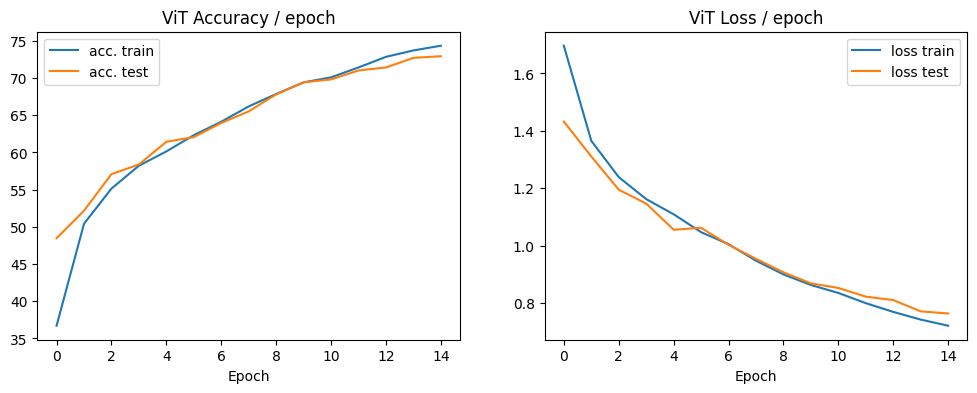

Epoch 15/15 (18s)	train: loss 0.7218, acc 74.35%	test: loss 0.7644, acc 72.94%


In [20]:
train_loader, test_loader = get_dataset("cifar10", batch_size=128, normalize=True, augment=True)
model = ViT(embed_dim=128, nb_blocks=4, patch_size=4)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)
acc_vit = main(model, train_loader, test_loader, optimizer, epochs=15, title="ViT")